# Figure 4: density change of the densest HLNA water in 8xCO2

Each year, the densest 5% of HLNA (50-65N) area by February-April surface sigma_1 is selected, and its mean T and S
are compared with the same selection in the control run. The densest set can move from year to year, so T and S
include the effect of the densest water changing location.

Inputs: `FMAASOmean_sigma1_cells_8x_natl20-80N_so75-50S.nc`, `FMAmean_TS_cells_8x_natl20-80N.nc`,
`surface_TS_sigma1_cells_ctrl_natl20-80N.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
years, change = common.densest_water_breakdown('8x')
for phase, (start, end) in {'collapsed 1000-2000': (1000, 2000), 'recovered 3000-4000': (3000, 4000)}.items():
    in_phase = (years >= start) & (years < end)
    print(f"{phase}: d_sigma {change['total'][in_phase].mean():+.2f} = temperature "
          f"{change['temperature'][in_phase].mean():+.2f} + salinity {change['salinity'][in_phase].mean():+.2f}")

collapsed 1000-2000: d_sigma -3.02 = temperature -0.46 + salinity -2.59
recovered 3000-4000: d_sigma -1.45 = temperature -1.72 + salinity +0.28


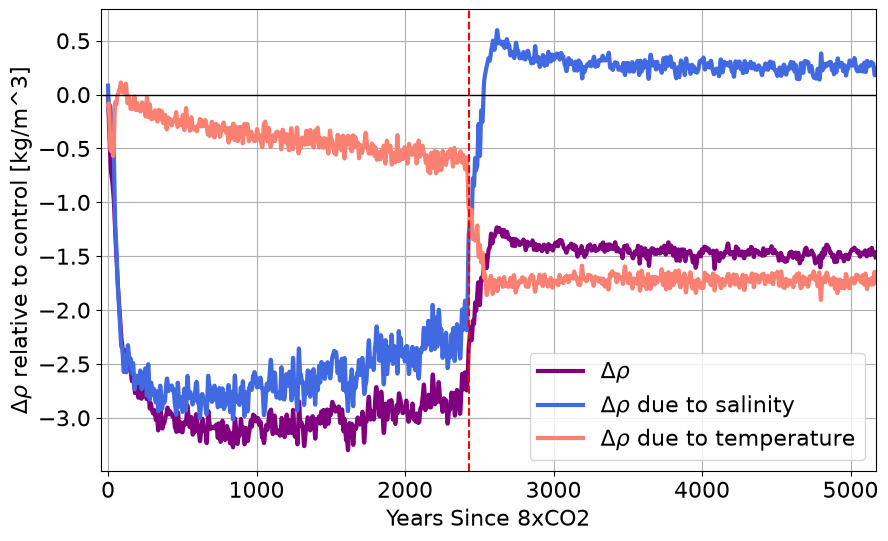

In [3]:
def plot_breakdown(ax, years, change, linewidth=3):
    """Draw the smoothed density change and its salinity and temperature parts on ax; zero is the control mean."""
    curves = [('total', '$\\Delta\\rho$', 'purple'),
              ('salinity', '$\\Delta\\rho$ due to salinity', 'royalblue'),
              ('temperature', '$\\Delta\\rho$ due to temperature', 'salmon')]
    for key, label, color in curves:
        ax.plot(years, common.butterworth_lowpass(change[key]), label=label, linewidth=linewidth, color=color)
    ax.axhline(0, color='k', linewidth=1)
    ax.grid()


fig, ax = plt.subplots(figsize=(10, 6))
plot_breakdown(ax, years, change)
ax.axvline(common.RECOVERY_YEAR, color='red', linestyle='--')
ax.set_xlim(years[0] - common.X_START_PAD, years[-1])
ax.set_xlabel('Years Since 8xCO2')
ax.set_ylabel('$\\Delta \\rho$ relative to control [kg/m^3]')
ax.legend()
plt.savefig(common.figure_path('fig04_density_breakdown_8x.png'), dpi=150, bbox_inches='tight')
plt.show()